# Matplotlib - Data Visualization:

**Definition:** `**Matplotlib**` is a Python library used to create static, animated, and interactive visualizations from numerical and categorical data.

It is commonly used with:
- NumPy — numerical arrays and mathematical calculations.
- Pandas — CSV files, Excel data, DataFrames, and data analysis.
- SciPy — statistical analysis and scientific computing.
- Scikit-learn — machine learning models and evaluation metrics.

**Learning outcomes**
- Understand Matplotlib's Figure/Axes model and create readable plots.
- Choose suitable charts for categorical, numerical, time-series, and statistical data.
- Use Pandas and NumPy to inspect data quality and visualize results.
- Visualize ML classification, regression, drift, fairness, and LLM evaluation results.
- Build reusable charts and automated QA reports.

**Suggested sequence:** work through the notebook from top to bottom. Run each code cell, change the sample data, and write down what changes in the chart.

### **Why should a QA or AI/ML Tester learn it?**

- Data quality testing - Identify missing values and unusual values.

- Exploratory Data Analysis (EDA) - 	Understand data distributions and relationships.

- Model testing	- Visualize predictions against actual values.

- Classification evaluation	- Plot confusion matrices and precision/recall.

- Performance testing	- Analyze response time, throughput, and latency.

- Regression testing	- Compare metrics across software or model versions.

- Data drift testing	- Compare production data with training data.

- Test reporting	- Generate charts for CI/CD reports and dashboards.


## 1. Setup and imports

Install in your activated virtual environment if needed:

```bash
python -m pip install matplotlib numpy pandas scikit-learn jupyter
```

In a notebook, `%matplotlib inline` is optional in most modern Jupyter setups. Do not put notebook magic commands in a regular `.py` file.

In [ ]:
pip install matplotlib numpy pandas scikit-learn jupyter

In [8]:
import matplotlib as plt
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.0.2
Pandas: 2.3.3


## 1.2 Understand the Matplotlib structure

| Component | Meaning |
| :--- | :--- |
| **Figure** | The complete canvas or output image. |
| **Axes** | The area where a chart is drawn. |
| **Axis** | The x-axis or y-axis, including ticks and scale. |
| **Title** | Describes the chart. |
| **Labels** | Explain what the x-axis and y-axis represent. |
| **Ticks** | Values or categories displayed along an axis. |
| **Legend** | Identifies different data series. |
| **Grid** | Helps compare values visually. |
| **Artist** | A general Matplotlib object drawn on a figure, including lines, text, and patches. |


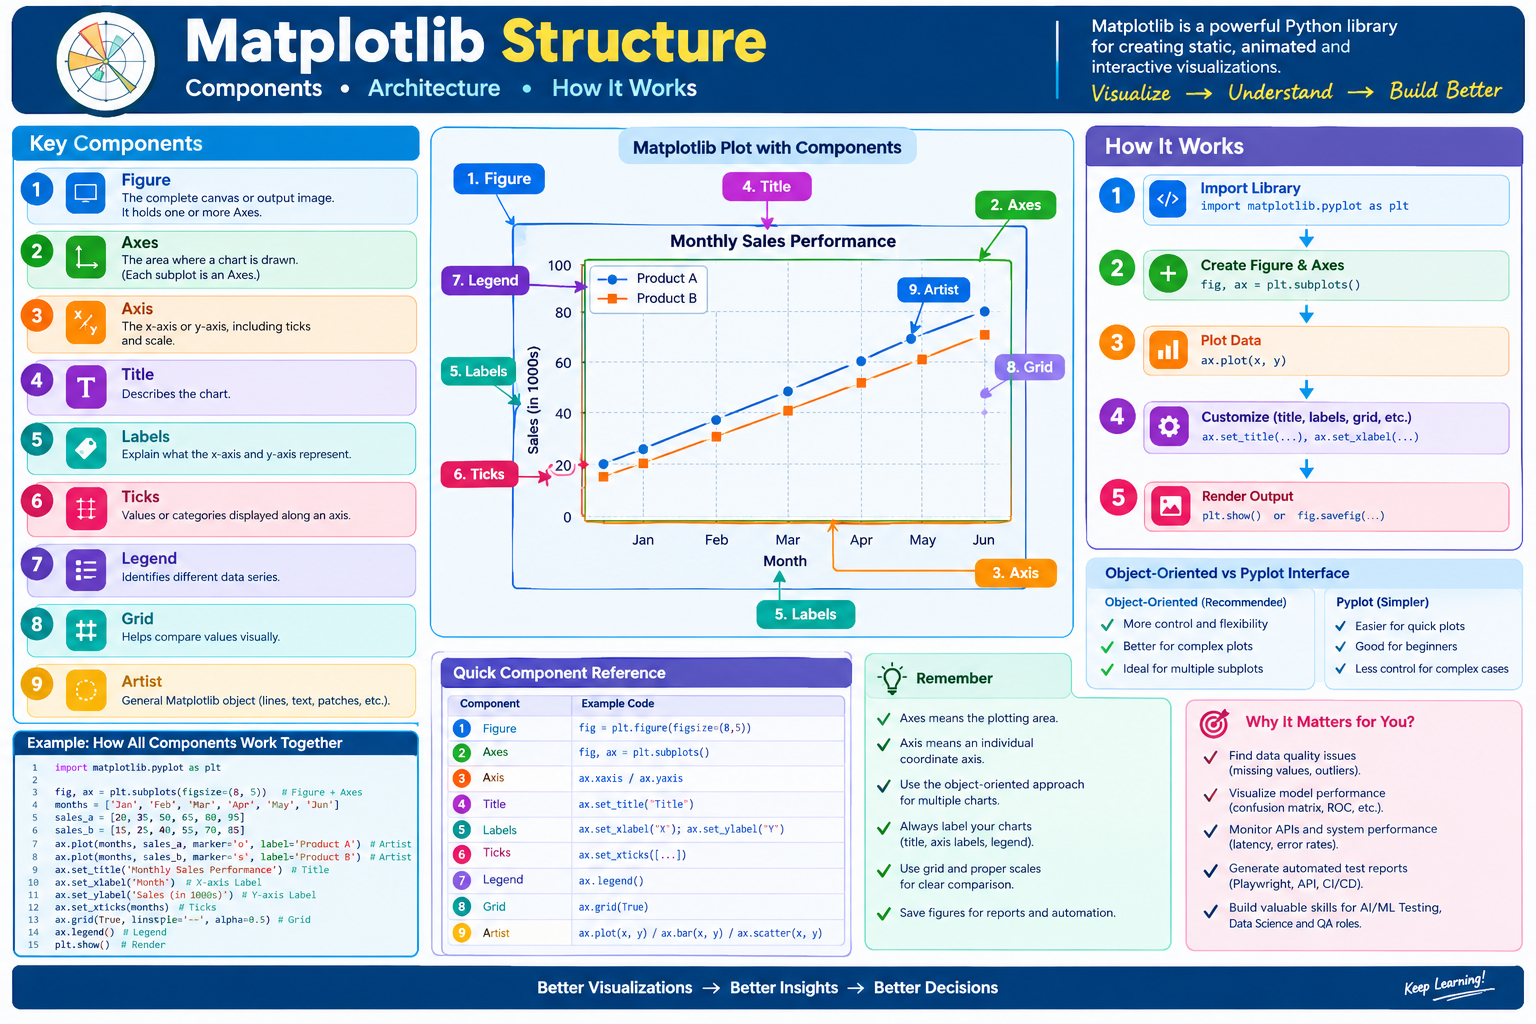

#### `1. Plot a Python List`
#### A list is ordered and allows duplicate values. It is useful for storing test results, marks, response times, and model scores.



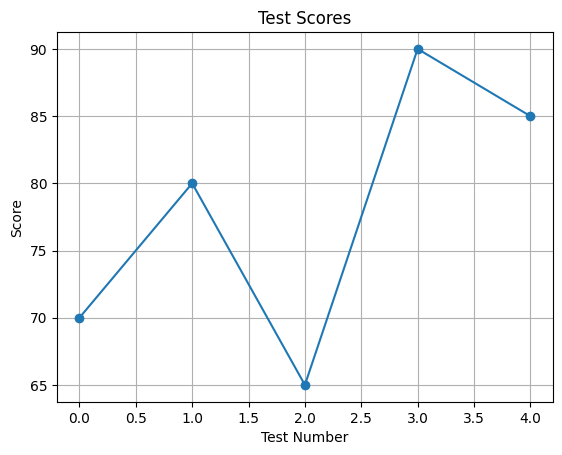

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# List data
test_scores = [70, 80, 65, 90, 85]

df=pd.DataFrame(test_scores)

# Plot the list
plt.plot(df, marker="o")
plt.grid()
plt.title("Test Scores")
plt.xlabel("Test Number")
plt.ylabel("Score")
plt.grid(True)

plt.show()

#### `2. Plot a Python Set`

A set stores unique values and does not guarantee a meaningful order. You can plot its values after converting them to a list or sorting them.

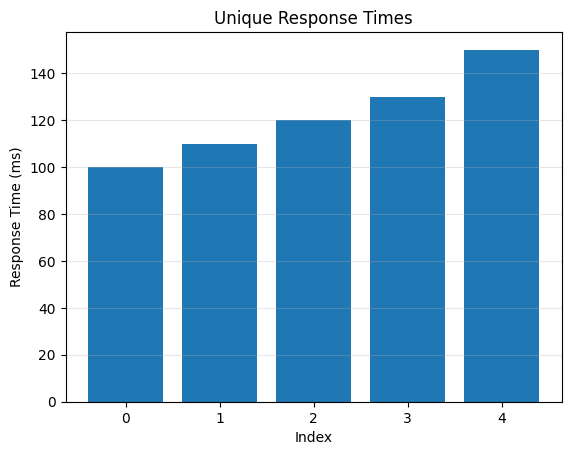

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Set data
response_times = {120, 100, 150, 110, 120, 130}

# Sort the unique values
values = sorted(response_times)

plt.bar(range(len(values)), values)

plt.title("Unique Response Times")

plt.xlabel("Index")

plt.ylabel("Response Time (ms)")

plt.grid(axis="y", alpha=0.3)




#### `3. Plot a Python Dictionary`

A dictionary stores key-value pairs. It is especially useful for plotting named categories and their corresponding values.

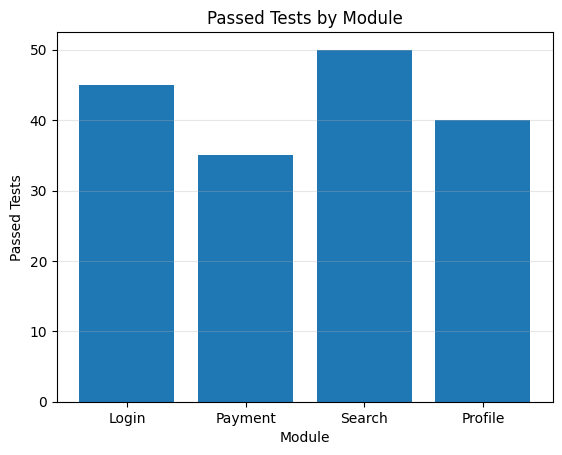

In [36]:
import matplotlib.pyplot as plt

# Dictionary data
test_results = {
    "Login": 45,
    "Payment": 35,
    "Search": 50,
    "Profile": 40
}

modules = list(test_results.keys())
passed_tests = list(test_results.values())

plt.bar(modules, passed_tests)

plt.title("Passed Tests by Module")
plt.xlabel("Module")
plt.ylabel("Passed Tests")
plt.grid(axis="y", alpha=0.3)

plt.show()

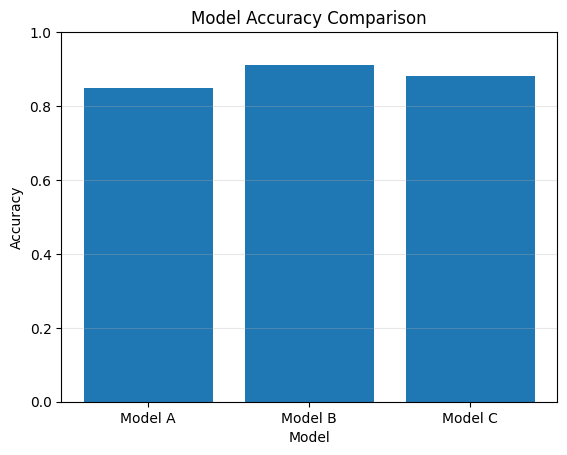

In [37]:
import matplotlib.pyplot as plt

results = [
    {"model": "Model A", "accuracy": 0.85},
    {"model": "Model B", "accuracy": 0.91},
    {"model": "Model C", "accuracy": 0.88}
]

models = [item["model"] for item in results]
accuracy = [item["accuracy"] for item in results]

plt.bar(models, accuracy)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

plt.show()

## 2. The Matplotlib object model

- **Figure (`fig`)**: the complete canvas.
- **Axes (`ax`)**: one plotting area inside a figure.
- **Axis**: an x- or y-coordinate axis, including ticks and scale.
- **Artists**: visible elements such as lines, text, patches, and legends.

Prefer the object-oriented pattern `fig, ax = plt.subplots()` for reusable scripts and reports.

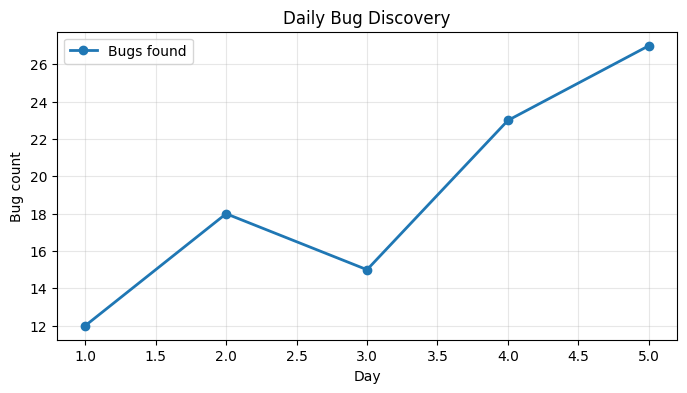

In [10]:
x = [1, 2, 3, 4, 5]
y = [12, 18, 15, 23, 27]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y, marker="o", linewidth=2, label="Bugs found")
ax.set(title="Daily Bug Discovery", xlabel="Day", ylabel="Bug count")
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

## 3. Figure size, resolution, layout, and saving

- `figsize=(width, height)` is measured in inches.
- `dpi` controls raster rendering resolution.
- `layout="constrained"` helps prevent labels and titles from overlapping.
- `fig.savefig(...)` saves a chart; `plt.close(fig)` frees resources in batch scripts.
- PNG works well for reports; PDF/SVG are useful for scalable output.

**QA tip:** chart presentation must not distort the data. Clearly label units and axis ranges.

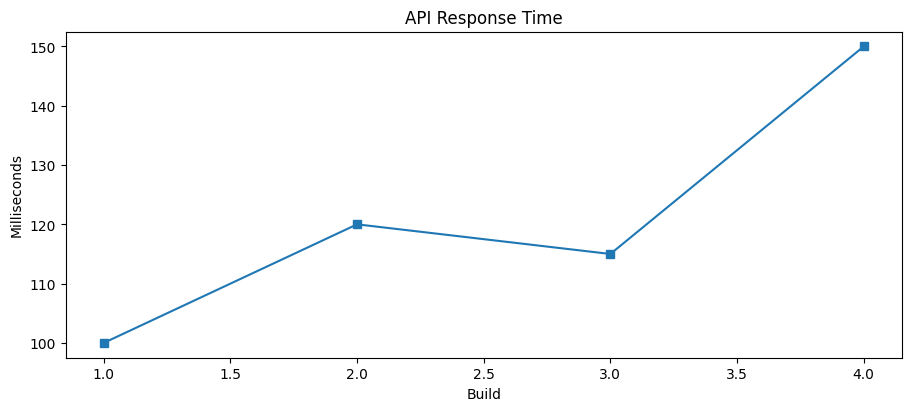

In [11]:
fig, ax = plt.subplots(figsize=(9, 4), dpi=100, layout="constrained")
ax.plot([1, 2, 3, 4], [100, 120, 115, 150], marker="s")
ax.set(title="API Response Time", xlabel="Build", ylabel="Milliseconds")
fig.savefig("api_response_time.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

## 4. Styling: color, marker, line, labels, limits, ticks, and grids

Common options include `color`, `linestyle`, `linewidth`, `marker`, `markersize`, `alpha`, and `label`.
Use color consistently, but do not rely on color alone to communicate meaning.

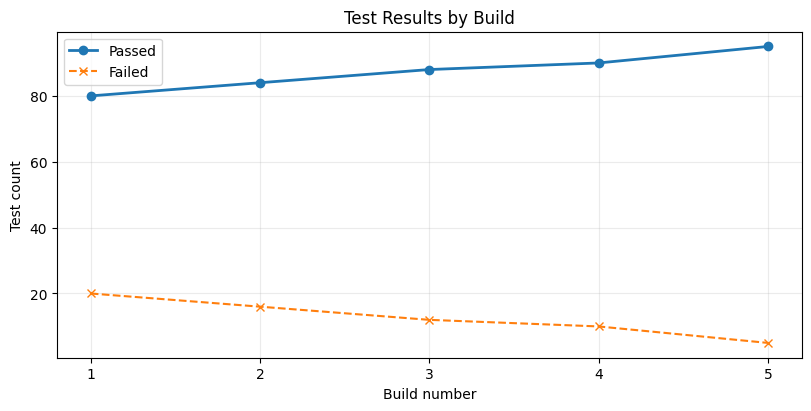

In [12]:
builds = np.arange(1, 6)
passed = [80, 84, 88, 90, 95]
failed = [20, 16, 12, 10, 5]

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(builds, passed, marker="o", linewidth=2, label="Passed")
ax.plot(builds, failed, marker="x", linestyle="--", label="Failed")
ax.set(title="Test Results by Build", xlabel="Build number", ylabel="Test count")
ax.set_xticks(builds)
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()

## 5. Line charts

**Best for:** trends over ordered observations, especially time or build number.

**QA examples:** pass rate per build, latency over time, production error rate, model quality by release.

Avoid connecting unrelated categories with lines. If you plot percentages, label them and use sensible limits.

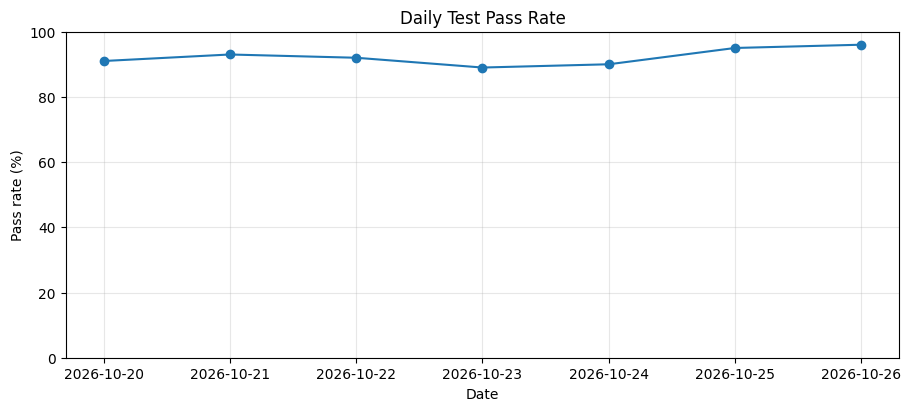

In [13]:
days = pd.date_range("2026-10-20", periods=7, freq="D")
pass_rate = [91, 93, 92, 89, 90, 95, 96]

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.plot(days, pass_rate, marker="o")
ax.set(title="Daily Test Pass Rate", xlabel="Date", ylabel="Pass rate (%)")
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
plt.show()

## 6. Bar charts: vertical, horizontal, grouped, and stacked

**Best for:** comparing discrete categories such as modules, browsers, models, or defect types.

- `ax.bar()` vertical bars
- `ax.barh()` horizontal bars
- Multiple bar calls with offsets create grouped bars.
- `bottom=` creates stacked bars.

For stacked test outcomes, make sure all categories are included and totals reconcile with source results.

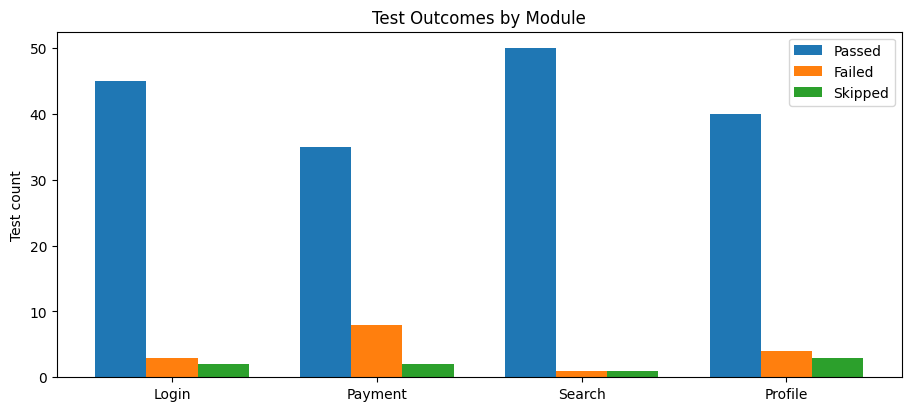

In [14]:
modules = ["Login", "Payment", "Search", "Profile"]
passed = np.array([45, 35, 50, 40])
failed = np.array([3, 8, 1, 4])
skipped = np.array([2, 2, 1, 3])
x = np.arange(len(modules))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.bar(x - width, passed, width, label="Passed")
ax.bar(x, failed, width, label="Failed")
ax.bar(x + width, skipped, width, label="Skipped")
ax.set_xticks(x, modules)
ax.set(title="Test Outcomes by Module", ylabel="Test count")
ax.legend()
plt.show()

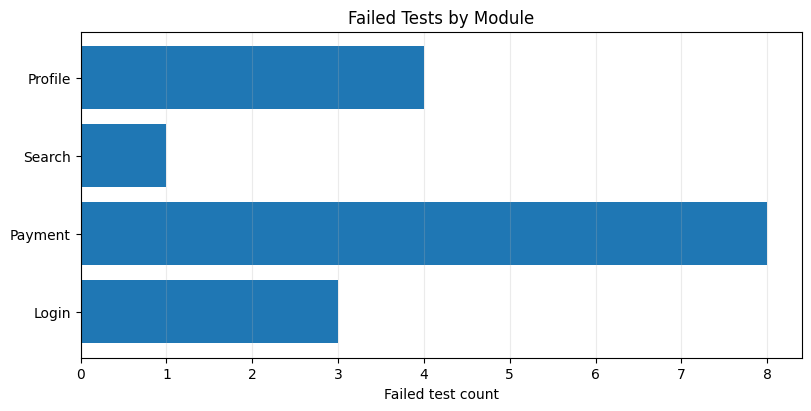

In [15]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.barh(modules, failed)
ax.set(title="Failed Tests by Module", xlabel="Failed test count")
ax.grid(axis="x", alpha=0.25)
plt.show()

## 7. Scatter plots

**Best for:** relationships between two numerical variables, clusters, and potential outliers.

Examples: request size vs latency, model confidence vs correctness, feature value vs prediction error.

A scatter plot can show association, but it does not prove causation.

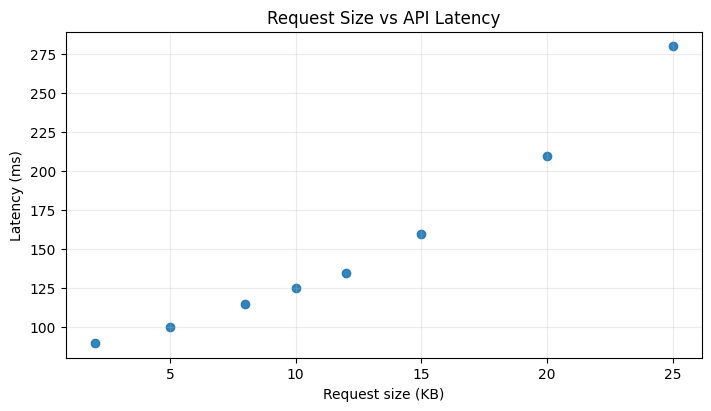

In [29]:
request_kb = [2, 5, 8, 10, 12, 15, 20, 25]
latency_ms = [90, 100, 115, 125, 135, 160, 210, 280]

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.scatter(request_kb, latency_ms, alpha=0.9)
ax.set(title="Request Size vs API Latency",
       xlabel="Request size (KB)", ylabel="Latency (ms)")
ax.grid(True, alpha=0.25)
plt.show()

## 8. Histograms and distributions

A histogram groups numerical values into bins. It can reveal skew, multiple peaks, spread, and long tails.

- `bins`: number of bins or explicit bin edges.
- `density=True`: scales the histogram to density rather than raw counts.
- Bin choices affect appearance, so compare charts using sensible, consistent bins.

**QA examples:** response-time distribution, model score distribution, test execution durations.

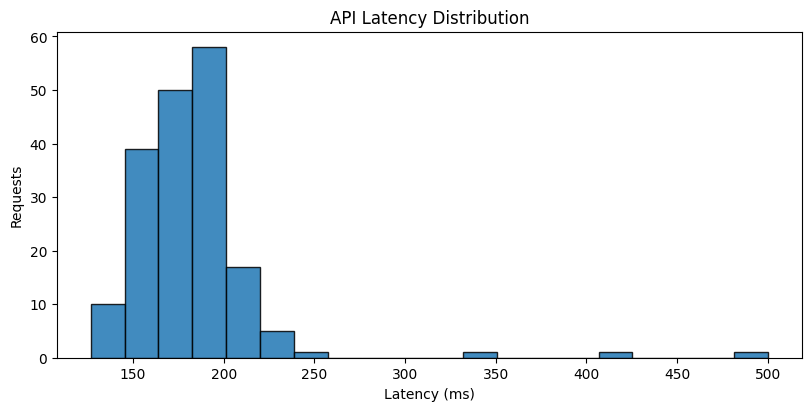

In [17]:
rng = np.random.default_rng(42)
latency = np.concatenate([rng.normal(180, 25, 180), [350, 420, 500]])

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.hist(latency, bins=20, edgecolor="black", alpha=0.85)
ax.set(title="API Latency Distribution", xlabel="Latency (ms)", ylabel="Requests")
plt.show()

## 9. Box plots and violin plots

A box plot summarizes the median, quartiles, whiskers, and potential fliers. By default, whiskers typically extend to the most extreme observations within 1.5 × IQR of the quartiles.

A violin plot adds a smoothed density estimate. Density estimates can be misleading for very small samples.

**Important:** an outlier is a candidate for investigation, not automatically bad data.

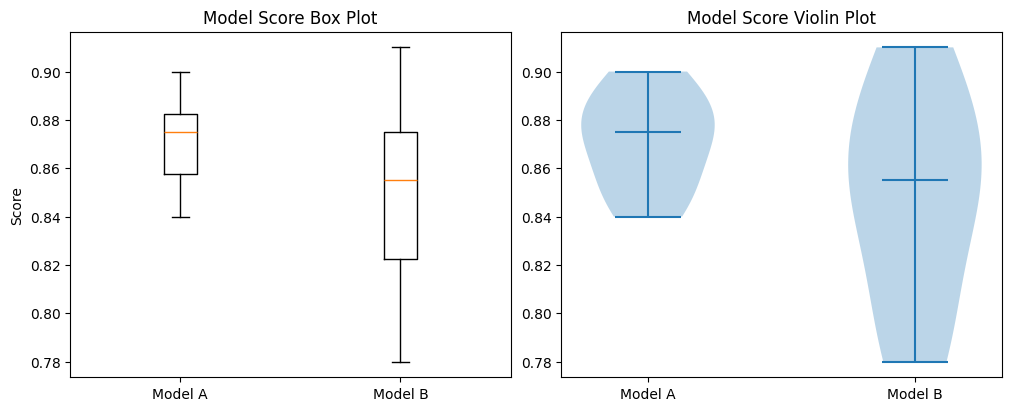

In [18]:
model_a = [0.84, 0.86, 0.88, 0.87, 0.89, 0.90, 0.85, 0.88]
model_b = [0.80, 0.83, 0.85, 0.87, 0.89, 0.78, 0.91, 0.86]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].boxplot([model_a, model_b], tick_labels=["Model A", "Model B"])
axes[0].set(title="Model Score Box Plot", ylabel="Score")
axes[1].violinplot([model_a, model_b], showmedians=True)
axes[1].set(title="Model Score Violin Plot")
axes[1].set_xticks([1, 2], ["Model A", "Model B"])
plt.show()

## 10. Pie/donut charts and area charts

Pie charts are suitable only for a small number of categories that form a meaningful whole. Bar charts are usually easier for precise comparisons.

`fill_between()` shades the area between two curves and is useful for uncertainty bands or acceptable ranges.

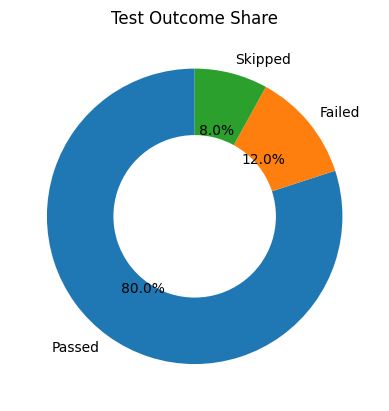

In [19]:
labels = ["Passed", "Failed", "Skipped"]
counts = [80, 12, 8]

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
ax.pie(counts, labels=labels, autopct="%1.1f%%", startangle=90,
       wedgeprops={"width": 0.45})
ax.set_title("Test Outcome Share")
plt.show()

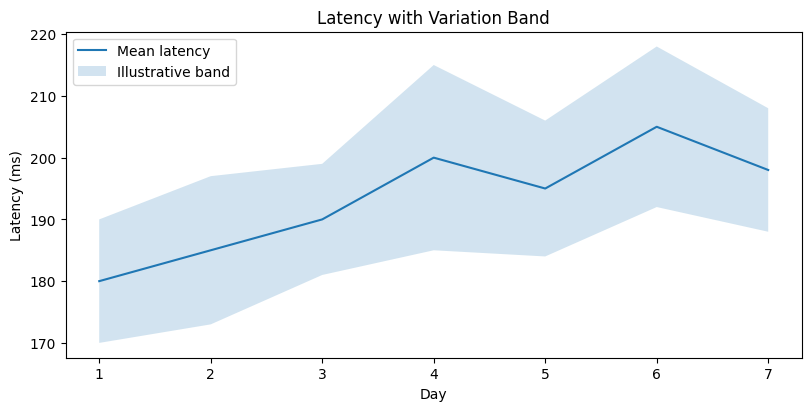

In [20]:
x = np.arange(1, 8)
mean_latency = np.array([180, 185, 190, 200, 195, 205, 198])
margin = np.array([10, 12, 9, 15, 11, 13, 10])

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(x, mean_latency, label="Mean latency")
ax.fill_between(x, mean_latency - margin, mean_latency + margin,
                alpha=0.2, label="Illustrative band")
ax.set(title="Latency with Variation Band", xlabel="Day", ylabel="Latency (ms)")
ax.legend()
plt.show()

## 11. Subplots and dashboard layouts

Use subplots to compare related metrics in a single figure. `sharex=True` or `sharey=True` is useful when scales should match. Use constrained layout to reduce overlap.

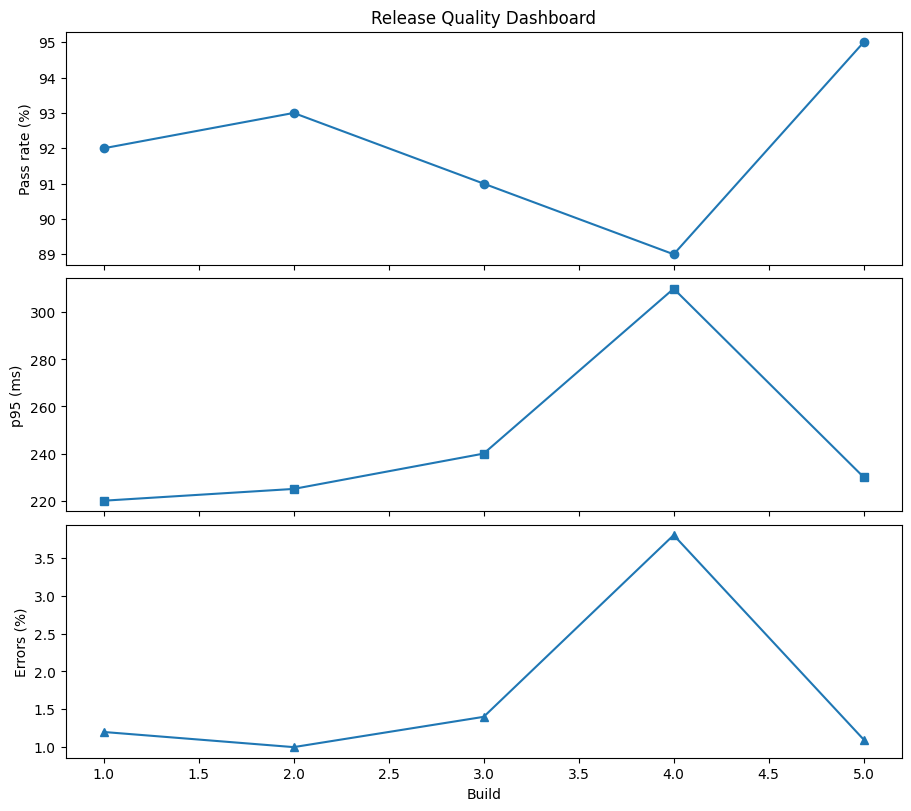

In [21]:
builds = np.arange(1, 6)
pass_rate = [92, 93, 91, 89, 95]
p95_latency = [220, 225, 240, 310, 230]
error_rate = [1.2, 1.0, 1.4, 3.8, 1.1]

fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True,
                         layout="constrained")
axes[0].plot(builds, pass_rate, marker="o")
axes[0].set_ylabel("Pass rate (%)")
axes[0].set_title("Release Quality Dashboard")

axes[1].plot(builds, p95_latency, marker="s")
axes[1].set_ylabel("p95 (ms)")

axes[2].plot(builds, error_rate, marker="^")
axes[2].set_ylabel("Errors (%)")
axes[2].set_xlabel("Build")

plt.show()

## 12. Heatmaps and correlation

`imshow()` maps matrix values to colors. Add a colorbar and labels so the scale is interpretable.

Correlation ranges from -1 to +1 for Pearson correlation. Zero indicates no linear correlation, not necessarily no relationship. Correlation does not prove causation.

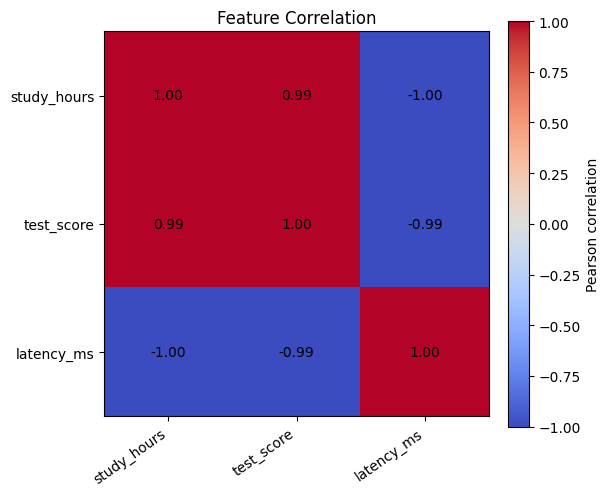

In [22]:
df_features = pd.DataFrame({
    "study_hours": [1, 2, 3, 4, 5, 6],
    "test_score": [50, 55, 65, 70, 82, 90],
    "latency_ms": [300, 280, 260, 240, 220, 200]
})
corr = df_features.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=35, ha="right")
ax.set_yticks(range(len(corr.columns)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Feature Correlation")
plt.show()

## 13. Data-quality visualizations: missing values and outliers

Always inspect the underlying data and validate assumptions. A chart can reveal suspicious patterns but cannot decide whether a value is incorrect.

Typical checks:
- Missing values and unexpected nulls
- Duplicate records and IDs
- Invalid ranges and category values
- Distribution changes and extreme values
- Data leakage and inconsistent preprocessing

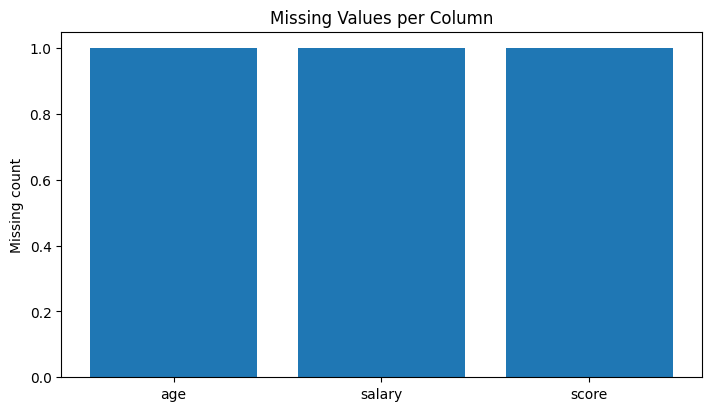

In [23]:
quality_df = pd.DataFrame({
    "age": [22, 30, np.nan, 40, 35, 29],
    "salary": [30000, np.nan, 50000, 65000, 55000, 42000],
    "score": [80, 85, 90, np.nan, 95, 88]
})

missing = quality_df.isna().sum()

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.bar(missing.index, missing.values)
ax.set(title="Missing Values per Column", ylabel="Missing count")
plt.show()

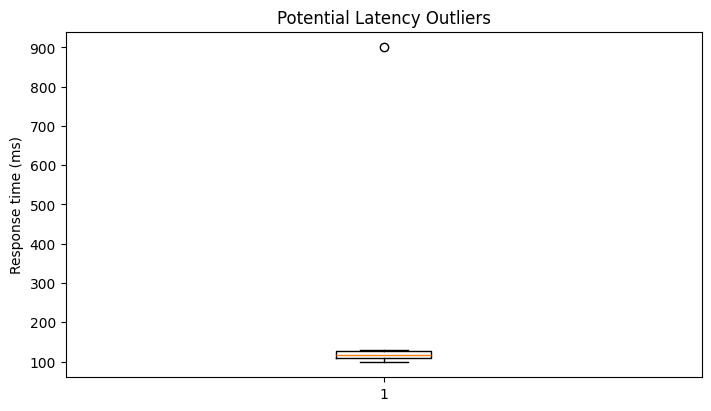

In [24]:
response_times = np.array([100, 105, 110, 115, 120, 125, 130, 900])

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
ax.boxplot(response_times)
ax.set(title="Potential Latency Outliers", ylabel="Response time (ms)")
plt.show()

## 14. Confusion matrix for classification

A confusion matrix compares actual labels with predicted labels.

- TP: actual positive, predicted positive
- TN: actual negative, predicted negative
- FP: actual negative, predicted positive
- FN: actual positive, predicted negative

A confusion matrix is especially useful when false positives and false negatives have different costs.

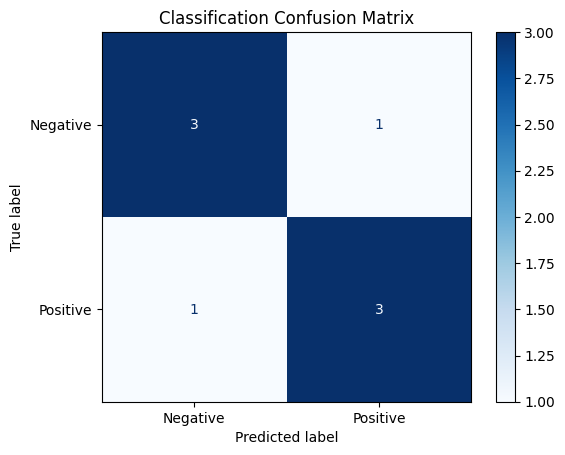

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

actual = [0, 0, 0, 1, 1, 1, 1, 0]
predicted = [0, 0, 1, 1, 0, 1, 1, 0]

cm = confusion_matrix(actual, predicted, labels=[0, 1])
display = ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"])
display.plot(cmap="Blues", values_format="d")
plt.title("Classification Confusion Matrix")
plt.show()

## 15. ROC and precision-recall curves

ROC plots true-positive rate against false-positive rate across thresholds. ROC-AUC measures ranking ability, but does not guarantee calibration or good performance at a chosen threshold.

Precision-recall curves are often useful for imbalanced data. Always document the positive class and the evaluation dataset.

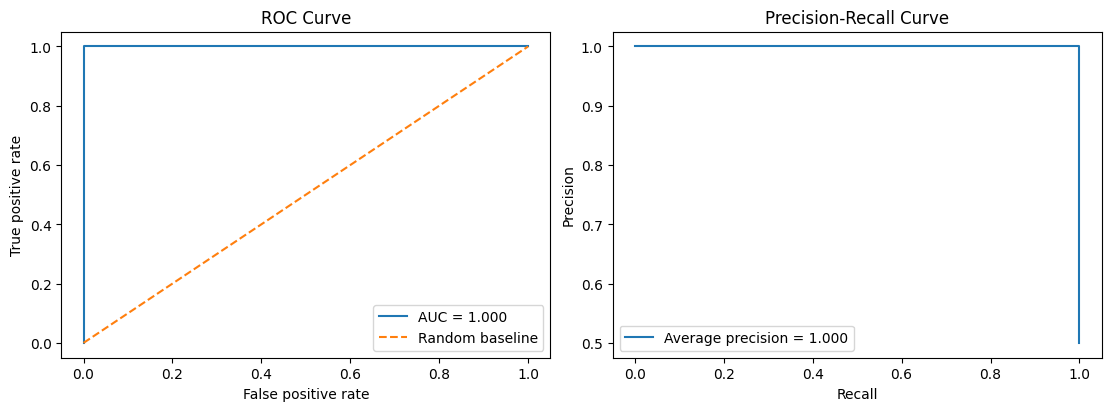

In [26]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve, average_precision_score

actual = [0, 0, 0, 1, 1, 1]
scores = [0.10, 0.30, 0.40, 0.55, 0.75, 0.90]

fpr, tpr, roc_thresholds = roc_curve(actual, scores)
auc = roc_auc_score(actual, scores)
precision, recall, pr_thresholds = precision_recall_curve(actual, scores)
ap = average_precision_score(actual, scores)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(fpr, tpr, label=f"AUC = {auc:.3f}")
axes[0].plot([0, 1], [0, 1], "--", label="Random baseline")
axes[0].set(title="ROC Curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()

axes[1].plot(recall, precision, label=f"Average precision = {ap:.3f}")
axes[1].set(title="Precision-Recall Curve", xlabel="Recall", ylabel="Precision")
axes[1].legend()
plt.show()

## 16. Regression predictions and residuals

A predicted-versus-actual plot shows how close predictions are to the ideal diagonal. Residuals are `actual - predicted`; residual patterns can reveal bias, nonlinearity, changing variance, and unusual observations.

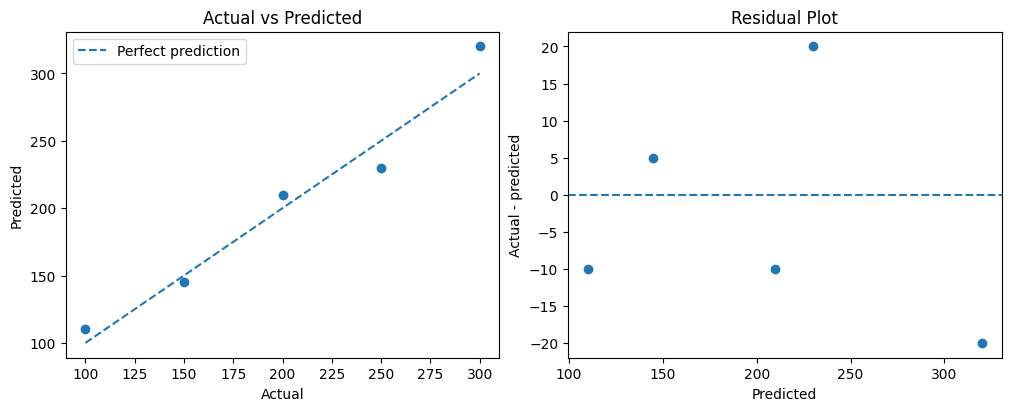

In [27]:
actual = np.array([100, 150, 200, 250, 300])
predicted = np.array([110, 145, 210, 230, 320])
residuals = actual - predicted

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
axes[0].scatter(actual, predicted)
axes[0].plot([100, 300], [100, 300], "--", label="Perfect prediction")
axes[0].set(title="Actual vs Predicted", xlabel="Actual", ylabel="Predicted")
axes[0].legend()

axes[1].scatter(predicted, residuals)
axes[1].axhline(0, linestyle="--")
axes[1].set(title="Residual Plot", xlabel="Predicted", ylabel="Actual - predicted")
plt.show()

## 17. Time-series monitoring and control charts

Use time-series charts for latency, throughput, error rate, drift metrics, and model quality. Monitor percentiles such as p50/p95/p99 in addition to averages.

Control limits should be estimated from an appropriate stable baseline. They are not automatically equal to business or SLO thresholds.

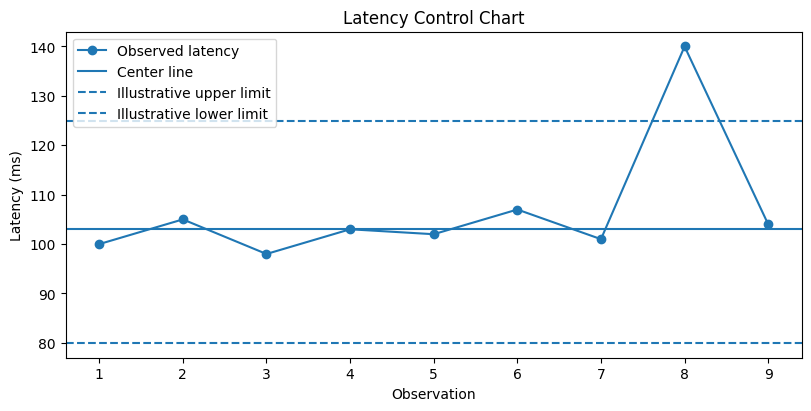

In [28]:
latency = np.array([100, 105, 98, 103, 102, 107, 101, 140, 104])
observations = np.arange(1, len(latency) + 1)
center = 103
upper_limit = 125
lower_limit = 80

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(observations, latency, marker="o", label="Observed latency")
ax.axhline(center, label="Center line")
ax.axhline(upper_limit, linestyle="--", label="Illustrative upper limit")
ax.axhline(lower_limit, linestyle="--", label="Illustrative lower limit")
ax.set(title="Latency Control Chart", xlabel="Observation", ylabel="Latency (ms)")
ax.legend()
plt.show()

## 18. Data drift visualization

- **Data drift:** input feature distribution changes.
- **Concept drift:** the relationship between inputs and target changes.
- **Performance degradation:** model quality worsens; it may or may not be caused by drift.

Plots are useful for investigation. Pair them with appropriate metrics such as PSI, Kolmogorov–Smirnov statistics, Jensen–Shannon divergence, and production outcome monitoring. Thresholds depend on context and sample size.

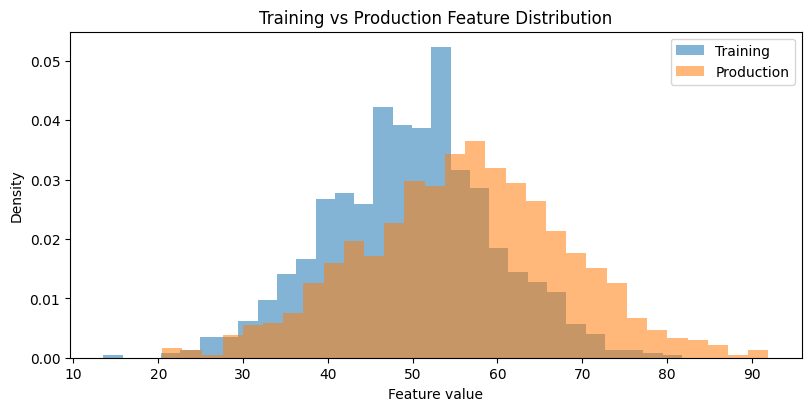

In [29]:
rng = np.random.default_rng(42)
training = rng.normal(50, 10, 1000)
production = rng.normal(57, 12, 1000)

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.hist(training, bins=30, density=True, alpha=0.55, label="Training")
ax.hist(production, bins=30, density=True, alpha=0.55, label="Production")
ax.set(title="Training vs Production Feature Distribution",
       xlabel="Feature value", ylabel="Density")
ax.legend()
plt.show()

## 19. LLM and AI-agent evaluation charts

For generative AI, visualize:
- Correctness, groundedness, retrieval relevance
- Safety and refusal behavior
- Prompt-injection success rate
- Task completion and tool-call success
- Latency, token usage, and cost per request
- Model-version regressions

Use the same evaluation set and metric definitions for fair comparisons. Include sample sizes and uncertainty when possible. Treat LLM-as-a-judge results as measurements that require validation.

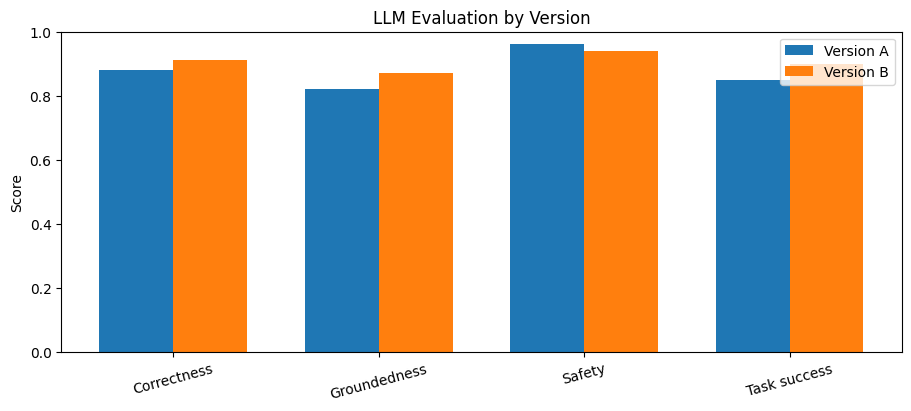

In [30]:
metrics = ["Correctness", "Groundedness", "Safety", "Task success"]
version_a = [0.88, 0.82, 0.96, 0.85]
version_b = [0.91, 0.87, 0.94, 0.90]

x = np.arange(len(metrics))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.bar(x - width/2, version_a, width, label="Version A")
ax.bar(x + width/2, version_b, width, label="Version B")
ax.set_xticks(x, metrics, rotation=15)
ax.set_ylim(0, 1)
ax.set(title="LLM Evaluation by Version", ylabel="Score")
ax.legend()
plt.show()

## 20. Annotations, logarithmic scales, and secondary axes

- `ax.annotate()` adds explanatory labels and arrows.
- `ax.set_yscale("log")` helps when positive values span orders of magnitude.
- `ax.twinx()` creates a second y-axis. Use sparingly and label units clearly because dual axes can mislead.

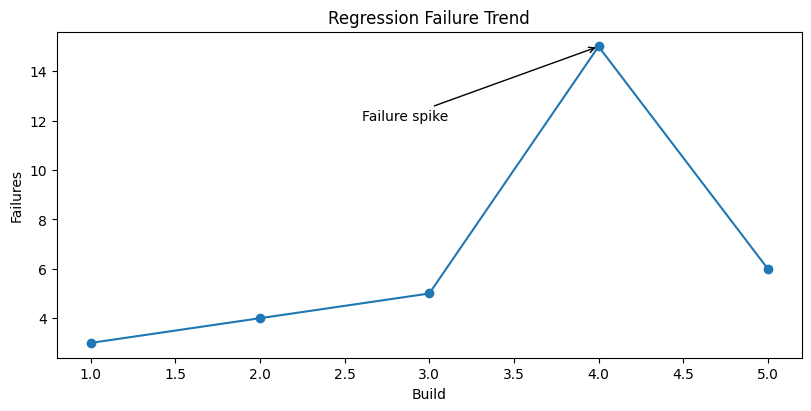

In [31]:
builds = np.arange(1, 6)
failures = [3, 4, 5, 15, 6]

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(builds, failures, marker="o")
ax.annotate("Failure spike", xy=(4, 15), xytext=(2.6, 12),
            arrowprops={"arrowstyle": "->"})
ax.set(title="Regression Failure Trend", xlabel="Build", ylabel="Failures")
plt.show()

## 21. Reusable chart function and automated report

Reusable functions help keep titles, labels, sizing, and file output consistent across a test-reporting framework.

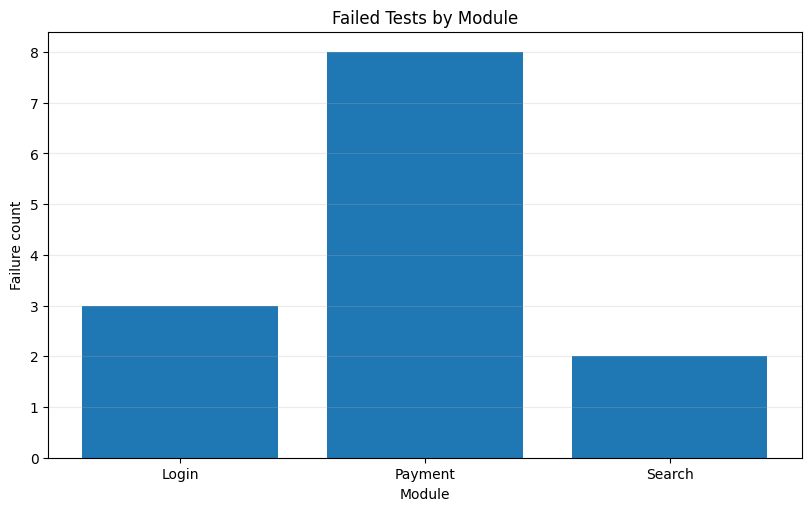

In [32]:
def create_bar_chart(categories, values, title, xlabel, ylabel, output_file=None):
    fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
    ax.bar(categories, values)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(axis="y", alpha=0.25)

    if output_file:
        fig.savefig(output_file, dpi=200, bbox_inches="tight")

    return fig, ax

fig, ax = create_bar_chart(
    ["Login", "Payment", "Search"],
    [3, 8, 2],
    "Failed Tests by Module",
    "Module",
    "Failure count",
    "failed_tests_by_module.png"
)
plt.show()
plt.close(fig)

## 22. QA report data validation

Example expected CSV columns: `module`, `passed`, `failed`, `skipped`.

Checks before plotting:
- Required columns exist.
- Module names are not missing or duplicated.
- Counts are numeric, non-negative integers.
- Source totals reconcile with the test runner.
- Data is from the intended build and timestamp.

Never let a chart silently hide malformed test results.

In [33]:
qa_df = pd.DataFrame({
    "module": ["Login", "Payment", "Search"],
    "passed": [45, 35, 50],
    "failed": [3, 8, 1],
    "skipped": [2, 2, 1]
})

required = {"module", "passed", "failed", "skipped"}
assert required.issubset(qa_df.columns)
assert qa_df["module"].notna().all()
assert qa_df["module"].is_unique

count_cols = ["passed", "failed", "skipped"]
assert qa_df[count_cols].notna().all().all()
assert (qa_df[count_cols] >= 0).all().all()
assert (qa_df[count_cols] % 1 == 0).all().all()

print("Report data checks passed.")

Report data checks passed.


## 23. Common errors and troubleshooting

| Problem | Fix |
|---|---|
| `ModuleNotFoundError` | Activate the right virtual environment; install with `python -m pip install matplotlib`. |
| Chart not displayed | Check `plt.show()` and notebook/backend setup. |
| Overlapping labels | Use `layout="constrained"` or `fig.tight_layout()`. |
| Wrong chart values | Validate types, filters, missing data, and aggregations. |
| Memory grows in loops | Save and call `plt.close(fig)`. |
| No `jupyter` command | Install Jupyter in the active environment or use `python -m jupyter notebook`. |
| Boxplot `tick_labels` error | Check Matplotlib version; older versions may use `labels`. |
| Misleading comparisons | Check units, denominators, axis limits, sample size, and uncertainty. |

## 24. Practice exercises

1. Plot weekly pass rates and add a target line at 95%.
2. Build a grouped bar chart comparing Chrome, Firefox, and Safari failures.
3. Plot API latency as a histogram and box plot; explain the difference.
4. Find missing values in a DataFrame and visualize them.
5. Plot a confusion matrix and explain FP and FN in your use case.
6. Compare ROC and precision-recall curves for imbalanced classification.
7. Compare training and production distributions and calculate a drift metric.
8. Create a report function that saves a PNG for each module.
9. Add a deployment annotation to a time-series chart.
10. Build a small LLM evaluation dashboard comparing two versions across correctness, safety, latency, and cost.

## 25. Suggested learning plan

- **Week 1:** figures, axes, line/bar/scatter, styling.
- **Week 2:** distributions, box/violin plots, subplots, annotations.
- **Week 3:** Pandas EDA, missing values, outliers, correlation.
- **Week 4:** statistics, time series, uncertainty, control charts.
- **Week 5:** confusion matrix, ROC/PR, regression diagnostics.
- **Week 6:** drift, fairness, LLM evaluation, performance monitoring.
- **Week 7:** reusable functions, CSV/JSON inputs, automated reports.
- **Week 8:** end-to-end portfolio project and README.

## 26. Official resources

- Matplotlib tutorials: https://matplotlib.org/stable/tutorials/index.html
- Quick start: https://matplotlib.org/stable/users/explain/quick_start.html
- Axes introduction: https://matplotlib.org/stable/users/explain/axes/axes_intro.html
- Cheat sheets: https://matplotlib.org/cheatsheets/
- Scikit-learn model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html

**Final reminder:** a visualization is evidence to investigate, not proof by itself. Pair charts with assertions, statistical reasoning, source-data validation, and domain-specific acceptance criteria.